# PMITC v1.0: load, join, plot a case
Labels are allegations by the named sources ("flagged by <source>"), not findings. The tables hold no personal names.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
DATA = '../data'
cases = pd.read_parquet(f'{DATA}/cases.parquet')
claims = pd.read_parquet(f'{DATA}/claims.parquet')
wallets = pd.read_parquet(f'{DATA}/wallets.parquet')
markets = pd.read_parquet(f'{DATA}/markets.parquet')
cases[['case_id','case_grade','investigation_outcome','n_claims','n_documented_by_case','benchmark_split']].sort_values('n_documented_by_case', ascending=False).head(15)

,case_id,case_grade,investigation_outcome,n_claims,n_documented_by_case,benchmark_split
60,us-iran-strike-2026-02-28,E4,unresolved,8,52,train
28,kpmg-earnings-2025-26,E4,unresolved,1,22,test
65,zachxbt-axiom-2026-02,E4,unresolved,3,10,train
34,nobel-peace-2025,E3,under_investigation,4,8,train
29,maduro-2026-01,E2,charged,10,7,train
58,us-iran-ceasefire-2026-04-07,E3,under_investigation,6,4,test
63,world-cup-2026-06,E4,unresolved,1,3,test
3,biden-pardons,E4,unresolved,2,2,test
5,bubblemaps-military-cluster,E4,unresolved,2,2,test
62,walz-vp-2024,E5,unresolved,1,1,train


In [2]:
# claims per grade and stance
pd.crosstab(claims.evidence_grade, claims.stance)

stance,alleges,clears,context,disputes
evidence_grade,,,,
E1,17,0,0,0
E2,5,0,0,0
E3,14,0,0,0
E4,22,2,0,0
E5,51,1,0,2
E6,7,0,1,1


In [3]:
# documented wallets (suspected and trade-confirmed) per case
wallets[wallets.is_documented].groupby('case_id').wallet.nunique().sort_values(ascending=False)

case_id
us-iran-strike-2026-02-28       52
kpmg-earnings-2025-26           22
zachxbt-axiom-2026-02           10
nobel-peace-2025                 8
maduro-2026-01                   7
us-iran-ceasefire-2026-04-07     4
world-cup-2026-06                3
biden-pardons                    2
bubblemaps-military-cluster      2
draftkings-pm-launch             1
mstr-btc-sale                    1
fed-chair-nomination-2026        1
google-yis-2025                  1
israel-rising-lion-2025-06       1
trump-pardon-cz-2025             1
taylor-swift-engagement          1
super-bowl-halftime-2026         1
walz-vp-2024                     1
Name: wallet, dtype: int64

## One case: the Maduro market
Minute price path of the Yes token around both news times, with the pre-news buys of documented wallets.

In [4]:
CASE = 'maduro-2026-01'
m = markets[markets.case_id == CASE]
mm = pd.read_parquet(f'{DATA}/market_minutes.parquet', filters=[('case_id','==',CASE), ('market_set','==','case')])
cid = mm[mm.t_news_version=='precise'].groupby('condition_id').usdc.sum().idxmax()
print(m.set_index('condition_id').loc[cid, ['question','t_news_utc','t_news_precise_utc','t_news_precise_precision']])

question                    Maduro out by January 31, 2026?
t_news_utc                        2026-01-03 00:00:00+00:00
t_news_precise_utc                2026-01-03 09:21:00+00:00
t_news_precise_precision                             minute
Name: 0x580adc1327de9bf7c179ef5aaffa3377bb5cb252b7d6390b027172d43fd6f993, dtype: object


                buyers  documented  controls
t_news_version                              
day               1400           3        30
precise           2096           6        69


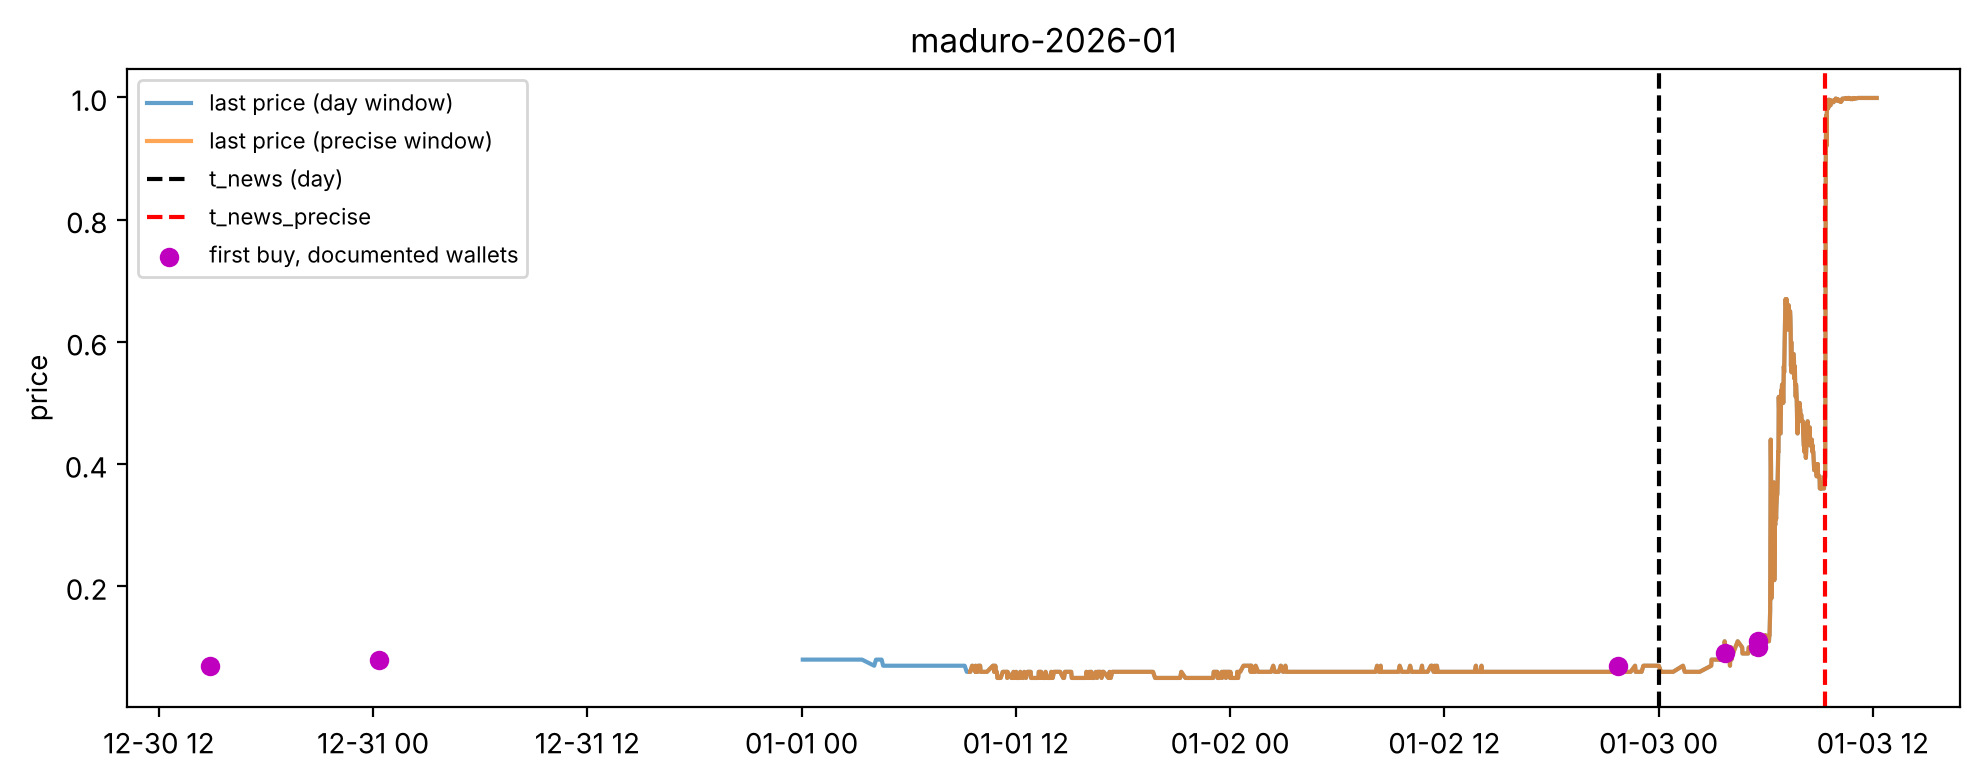

In [5]:
pos = pd.read_parquet(f'{DATA}/positions.parquet', filters=[('case_id','==',CASE), ('condition_id','==',cid)])
print(pos.groupby('t_news_version').agg(buyers=('wallet','nunique'), documented=('is_documented','sum'), controls=('is_control','sum')))
fig, ax = plt.subplots(figsize=(10,4))
for v, g in mm[mm.condition_id == cid].groupby('t_news_version'):
    ax.plot(g.minute_utc, g.last_price, label=f'last price ({v} window)', alpha=.7)
row = m.set_index('condition_id').loc[cid]
ax.axvline(row.t_news_utc, color='k', ls='--', label='t_news (day)'); ax.axvline(row.t_news_precise_utc, color='r', ls='--', label='t_news_precise')
d = pos[(pos.t_news_version=='precise') & pos.is_documented]
ax.scatter(pd.to_datetime(d.first_buy_ts, unit='s', utc=True), d.first_buy_price, color='m', zorder=5, label='first buy, documented wallets')
ax.legend(fontsize=8); ax.set_ylabel('price'); ax.set_title(CASE); plt.tight_layout()

## Joins
`positions` (all pre-news buyers) joins `wallets` on (wallet, case_id), `markets` on (case_id, condition_id), and `fills` on (condition_id, asset_id, wallet) with `ts < t_cut_ts`.

In [6]:
import duckdb
duckdb.sql(f"""SELECT market_set, source, count(*) legs FROM read_parquet('{DATA}/fills_part*.parquet') GROUP BY ALL ORDER BY 1, 2""").df()

,market_set,source,legs
0,case,data_api_v2,2131706
1,case,hf_polymarket_v1,20966634
2,label_other,data_api_v2,6158
3,label_other,hf_polymarket_v1,65752
4,placebo,hf_polymarket_v1,30260306
